# 🌴 Saudi Date Fruit Classifier
### Fine-tuning a pretrained ResNet-18 to recognise 9 varieties of Saudi dates

**Course:** Computer Vision for Developers — SDAIA Academy
**Team:** _Wejdan Alotaibi_ .

**Dataset:** [Date Fruit Image Dataset in Controlled Environment](https://www.kaggle.com/datasets/wadhasnalhamdan/date-fruit-image-dataset-in-controlled-environment) (Kaggle)

Saudi Arabia is one of the world's largest date producers, and telling varieties apart (Ajwa vs. Sokari vs. Medjool …) matters for sorting lines, markets and quality control. In this notebook we:

1. Download and inspect the dataset, then make a clean **train / validation / test** split.
2. Measure the model on the test set **before training** (it should be no better than guessing).
3. Fine-tune a **pretrained ResNet-18** with a new 9-class head (Day 2 technique).
4. Plot loss and accuracy per epoch.
5. Measure the **same test set with the same metrics after training** and compare in one table.
6. Look inside the model: confusion matrix, its mistakes, and **Grad-CAM** heat-maps.
7. Bonus: compare against a **small CNN trained from scratch** (Day 1 technique).

> ▶️ **Runtime → Change runtime type → T4 GPU**, then **Runtime → Run all**. The whole notebook runs well under 30 minutes.

## 0. Setup

In [1]:
# Check that a GPU is attached (Runtime → Change runtime type → T4 GPU)
!nvidia-smi -L
!pip install -q kagglehub

GPU 0: Tesla T4 (UUID: GPU-3a528114-78cf-7e16-b767-3930eeadc511)


In [2]:
import os, random, time, json, copy, hashlib, shutil, zipfile
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, models

from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)

SEED = 42
def set_seed(seed=SEED):
    """Same seed → same split, same initial weights, same shuffling."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
set_seed()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device, "|", torch.cuda.get_device_name(0) if device.type == "cuda" else "no GPU!")

# ---------------- Hyperparameters (stated once, used everywhere) ----------------
IMG_SIZE     = 224      # input size expected by ResNet
BATCH_SIZE   = 32
EPOCHS       = 12       # ResNet-18 fine-tuning
LR_HEAD      = 1e-3     # new classifier layer (random start) → larger learning rate
LR_BACKBONE  = 1e-4     # pretrained layers only need small adjustments
WEIGHT_DECAY = 1e-4
EPOCHS_CNN   = 20       # bonus: small CNN from scratch needs more epochs
LR_CNN       = 1e-3
NUM_WORKERS  = 2
RUN_BASELINE_CNN = True # set False to skip the bonus section

# ---------------- Colour theme: pink shades + brown only ----------------
from cycler import cycler
from matplotlib.colors import LinearSegmentedColormap
PINK_LIGHT, PINK, PINK_DARK = "#F8BBD0", "#EC407A", "#AD1457"
BROWN_LIGHT, BROWN, BROWN_DARK = "#C49A6C", "#8B5A2B", "#4E342E"
CMAP_PINK_BROWN = LinearSegmentedColormap.from_list("pink_brown", ["#FFF5F8", PINK_LIGHT, PINK, BROWN, BROWN_DARK])
CMAP_PINK_HEAT = LinearSegmentedColormap.from_list("pink_heat", ["#FFF5F8", PINK_LIGHT, PINK, PINK_DARK])
plt.rcParams.update({
    "axes.prop_cycle": cycler(color=[BROWN, PINK, BROWN_LIGHT, PINK_DARK]),
    "text.color": BROWN_DARK, "axes.titlecolor": BROWN_DARK, "axes.labelcolor": BROWN_DARK,
    "axes.edgecolor": BROWN, "xtick.color": BROWN_DARK, "ytick.color": BROWN_DARK, "grid.color": PINK_LIGHT,
})

FIG_DIR, RESULTS_DIR = Path("figures"), Path("results")
FIG_DIR.mkdir(exist_ok=True)
RESULTS_DIR.mkdir(exist_ok=True)

Device: cuda | Tesla T4


## 1. Dataset

**Source:** Kaggle — *Date Fruit Image Dataset in Controlled Environment* (W. Alhamdan & J. Howe, City, University of London).
Each image is a **single date fruit** photographed with a DSLR camera in a controlled environment (same background and lighting). There is one folder per variety.

**Kaggle credentials:** add `KAGGLE_USERNAME` and `KAGGLE_KEY` in Colab **Secrets** (🔑 icon in the left sidebar) and switch on *Notebook access*. The key is never written in this notebook.

In [3]:
# Read Kaggle credentials from Colab Secrets (never paste the key here)
try:
    from google.colab import userdata
    os.environ["KAGGLE_USERNAME"] = userdata.get("KAGGLE_USERNAME")
    os.environ["KAGGLE_KEY"] = userdata.get("KAGGLE_KEY")
    print("Kaggle credentials loaded from Colab Secrets ✅")
except Exception as e:
    print(f"Could not read Colab Secrets ({type(e).__name__}) – trying an anonymous download")

import kagglehub
KAGGLE_DATASET = "wadhasnalhamdan/date-fruit-image-dataset-in-controlled-environment"
raw_path = Path(kagglehub.dataset_download(KAGGLE_DATASET))
print("Downloaded to:", raw_path)

Could not read Colab Secrets (SecretNotFoundError) – trying an anonymous download
Using Colab cache for faster access to the 'date-fruit-image-dataset-in-controlled-environment' dataset.
Downloaded to: /kaggle/input/date-fruit-image-dataset-in-controlled-environment


In [4]:
IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

def is_image(p):
    # skip hidden/macOS helper files such as "._IMG_001.jpg"
    return p.is_file() and p.suffix.lower() in IMG_EXTS and not p.name.startswith(".")

def is_real_folder(d):
    return d.is_dir() and not d.name.startswith((".", "__"))   # skips __MACOSX, .ipynb_checkpoints …

def find_class_root(root):
    """Return the shallowest folder that has ≥ 2 sub-folders containing images (one sub-folder = one class)."""
    folders = sorted([root, *[p for p in root.rglob("*") if is_real_folder(p)]], key=lambda p: len(p.parts))
    for folder in folders:
        class_dirs = [d for d in folder.iterdir() if is_real_folder(d) and any(is_image(f) for f in d.rglob("*"))]
        if len(class_dirs) >= 2:
            return folder, sorted(class_dirs)
    raise RuntimeError(f"No class folders found under {root}")

class_root, class_dirs = find_class_root(raw_path)
print("Class folders found in:", class_root, "\n")
for d in class_dirs:
    print(f"  {d.name:<15} {sum(1 for f in d.rglob('*') if is_image(f)):>5} images")
print(f"\n{len(class_dirs)} classes (expected 9)")

example = next(f for f in class_dirs[0].rglob("*") if is_image(f))
with Image.open(example) as im:
    print(f"Example original photo: {example.name} – {im.size[0]}×{im.size[1]} px")

Class folders found in: /kaggle/input/date-fruit-image-dataset-in-controlled-environment 

  Ajwa              175 images
  Galaxy            190 images
  Medjool           135 images
  Meneifi           232 images
  Nabtat Ali        177 images
  Rutab             146 images
  Shaishe           171 images
  Sokari            264 images
  Sugaey            168 images

9 classes (expected 9)
Example original photo: Ajwa Date (73).JPG – 5184×3456 px


### 1.1 Clean copy: resize once + remove duplicates

The original photos are large DSLR images. Decoding them again in every epoch would be slow, so we resize every image **once** (shorter side = 256 px) into `data_clean/<class>/`.

While copying we compute an **MD5 hash** of every file and skip exact duplicates: a duplicate that lands in both train and test would leak the answer into the test set.

In [5]:
CLEAN_DIR = Path("data_clean")
SHORT_SIDE = 256

def resize_short_side(img, short=SHORT_SIDE):
    w, h = img.size
    scale = short / min(w, h)
    return img.resize((round(w * scale), round(h * scale)), Image.BICUBIC)

if CLEAN_DIR.exists():
    shutil.rmtree(CLEAN_DIR)          # always rebuild from scratch

seen_hashes, n_dupes, n_bad = set(), 0, 0
for class_dir in class_dirs:
    out_dir = CLEAN_DIR / class_dir.name
    out_dir.mkdir(parents=True)
    files = sorted(p for p in class_dir.rglob("*") if is_image(p))
    for f in tqdm(files, desc=f"{class_dir.name:<12}"):
        digest = hashlib.md5(f.read_bytes()).hexdigest()
        if digest in seen_hashes:      # exact duplicate → skip
            n_dupes += 1
            continue
        seen_hashes.add(digest)
        try:
            with Image.open(f) as img:
                img.draft("RGB", (2 * SHORT_SIDE, 2 * SHORT_SIDE))  # fast JPEG decode at a reduced size
                img = ImageOps.exif_transpose(img).convert("RGB")   # respect the camera's rotation tag
                resize_short_side(img).save(out_dir / f"{f.stem}_{digest[:6]}.jpg", quality=95)
        except Exception as e:         # unreadable file → skip it
            n_bad += 1
            print("  skipped", f.name, "-", e)

print(f"\nClean images: {len(seen_hashes) - n_bad} | duplicates removed: {n_dupes} | unreadable: {n_bad}")

Ajwa        :   0%|          | 0/175 [00:00<?, ?it/s]

Galaxy      :   0%|          | 0/190 [00:00<?, ?it/s]

Medjool     :   0%|          | 0/135 [00:00<?, ?it/s]

Meneifi     :   0%|          | 0/232 [00:00<?, ?it/s]

Nabtat Ali  :   0%|          | 0/177 [00:00<?, ?it/s]

Rutab       :   0%|          | 0/146 [00:00<?, ?it/s]

Shaishe     :   0%|          | 0/171 [00:00<?, ?it/s]

Sokari      :   0%|          | 0/264 [00:00<?, ?it/s]

Sugaey      :   0%|          | 0/168 [00:00<?, ?it/s]


Clean images: 1658 | duplicates removed: 0 | unreadable: 0


Total images: 1658 | classes: 9


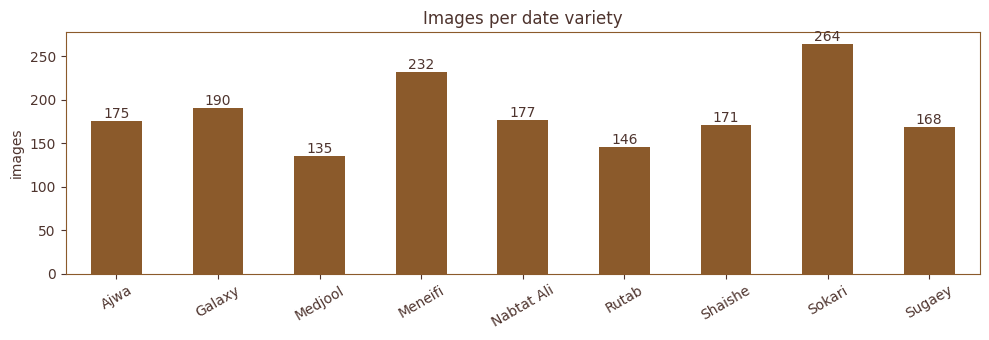

In [6]:
full_ds = datasets.ImageFolder(CLEAN_DIR)     # one sub-folder = one class
class_names = full_ds.classes
NUM_CLASSES = len(class_names)
targets = np.array(full_ds.targets)

counts = pd.Series(np.bincount(targets, minlength=NUM_CLASSES), index=class_names)
print(f"Total images: {len(full_ds)} | classes: {NUM_CLASSES}")

ax = counts.plot.bar(figsize=(10, 3.5), color=BROWN)
ax.bar_label(ax.containers[0])
ax.set_title("Images per date variety")
ax.set_ylabel("images")
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig(FIG_DIR / "class_counts.png", dpi=120)
plt.show()

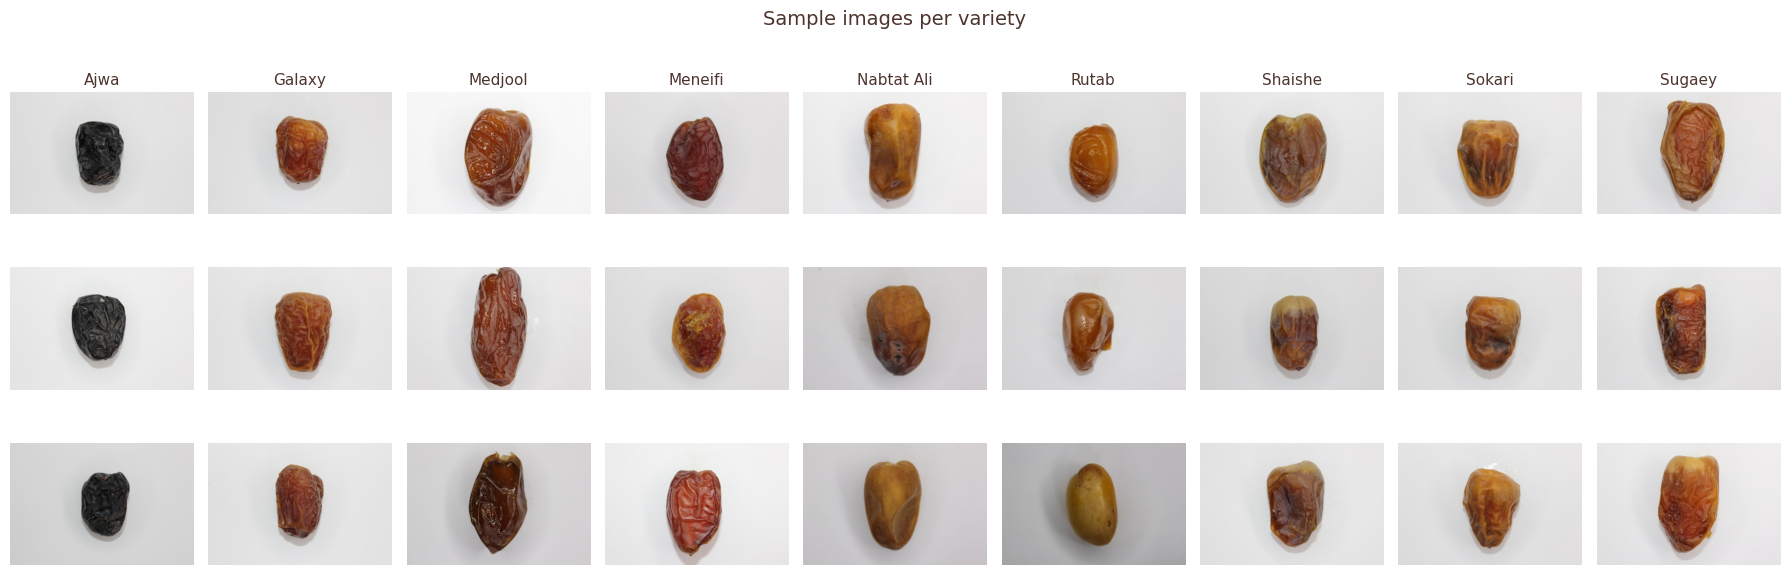

In [7]:
# Sample grid: 3 random images from every class
SAMPLES_PER_CLASS = 3
rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(SAMPLES_PER_CLASS, NUM_CLASSES, figsize=(2 * NUM_CLASSES, 2.1 * SAMPLES_PER_CLASS), squeeze=False)
for c, name in enumerate(class_names):
    picks = rng.choice(np.where(targets == c)[0], size=SAMPLES_PER_CLASS, replace=False)
    for r, i in enumerate(picks):
        axes[r, c].imshow(Image.open(full_ds.samples[i][0]))
        axes[r, c].axis("off")
    axes[0, c].set_title(name, fontsize=11)
plt.suptitle("Sample images per variety", fontsize=14)
plt.tight_layout()
plt.savefig(FIG_DIR / "samples.png", dpi=120, bbox_inches="tight")
plt.show()

### 1.2 Train / validation / test split

Stratified split **70 / 15 / 15** with a fixed seed, so every class keeps the same proportion in every split.

| split | used for |
|---|---|
| **train** | the model learns from it |
| **validation** | choosing the best epoch |
| **test** | locked away — used only twice: **before** and **after** training |

In [8]:
indices = np.arange(len(full_ds))
train_idx, temp_idx = train_test_split(indices, test_size=0.30, stratify=targets, random_state=SEED)
val_idx, test_idx = train_test_split(temp_idx, test_size=0.50, stratify=targets[temp_idx], random_state=SEED)

# Leakage check: no image may appear in two splits
assert set(train_idx).isdisjoint(val_idx)
assert set(train_idx).isdisjoint(test_idx)
assert set(val_idx).isdisjoint(test_idx)
print("No overlap between train / val / test ✅")

split_table = pd.DataFrame({
    "train": np.bincount(targets[train_idx], minlength=NUM_CLASSES),
    "val":   np.bincount(targets[val_idx],   minlength=NUM_CLASSES),
    "test":  np.bincount(targets[test_idx],  minlength=NUM_CLASSES),
}, index=pd.Index(class_names, name="Variety"))
split_table["total"] = split_table.sum(axis=1)
split_table.loc["TOTAL"] = split_table.sum()
split_table

No overlap between train / val / test ✅


,train,val,test,total
Variety,,,,
Ajwa,122,27,26,175
Galaxy,133,29,28,190
Medjool,94,20,21,135
Meneifi,162,35,35,232
Nabtat Ali,124,26,27,177
Rutab,102,22,22,146
Shaishe,120,25,26,171
Sokari,185,40,39,264
Sugaey,118,25,25,168


### 1.3 Transforms and data loaders

* **Train:** random crop/zoom, flips and small rotations → the model sees a slightly different date every epoch, which reduces overfitting. Brightness/contrast change only a little and we do **not** change the hue, because **colour is one of the main clues** that separates varieties.
* **Validation / test:** fixed resize + centre crop, no randomness.
* Normalise with the ImageNet mean/std, because the backbone was pretrained on ImageNet.

In [9]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

train_tf = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.7, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(20),
    transforms.ColorJitter(brightness=0.15, contrast=0.15),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
eval_tf = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(IMG_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

# Two views of the same folder: with augmentation (train) and without (val / test)
train_ds = Subset(datasets.ImageFolder(CLEAN_DIR, transform=train_tf), train_idx)
val_ds   = Subset(datasets.ImageFolder(CLEAN_DIR, transform=eval_tf), val_idx)
test_ds  = Subset(datasets.ImageFolder(CLEAN_DIR, transform=eval_tf), test_idx)

pin = device.type == "cuda"
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS,
                          pin_memory=pin, generator=torch.Generator().manual_seed(SEED))
val_loader   = DataLoader(val_ds,  batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=pin)
test_loader  = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=pin)
print(f"train {len(train_ds)} | val {len(val_ds)} | test {len(test_ds)} images")

train 1160 | val 249 | test 249 images


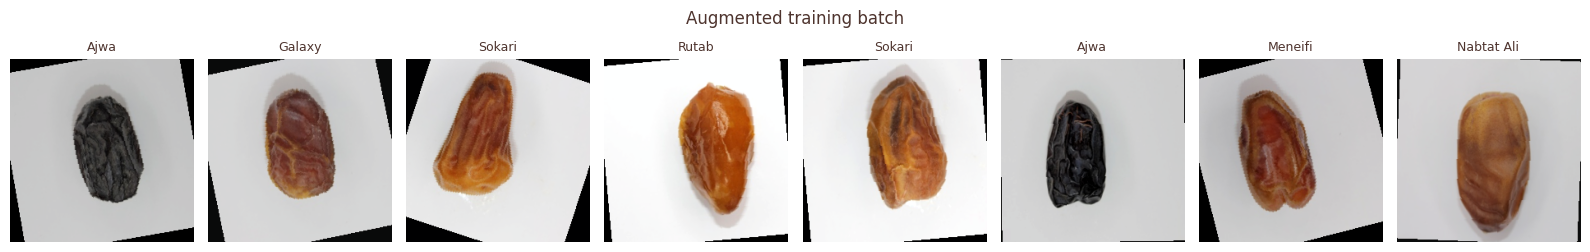

In [10]:
def denorm(t):
    """Undo Normalize so a tensor (3,H,W) can be shown with imshow."""
    img = t.permute(1, 2, 0).cpu().numpy() * np.array(STD) + np.array(MEAN)
    return img.clip(0, 1)

# What the model actually sees during training (augmented images)
xb, yb = next(iter(train_loader))
fig, axes = plt.subplots(1, 8, figsize=(16, 2.6))
for ax, x, y in zip(axes, xb, yb):
    ax.imshow(denorm(x))
    ax.set_title(class_names[y], fontsize=9)
    ax.axis("off")
plt.suptitle("Augmented training batch")
plt.tight_layout()
plt.show()

## 2. Model: pretrained ResNet-18 with a new head

ResNet-18 was pretrained on ImageNet (≈1.2 M images, 1000 classes), so its layers already detect edges, textures and shapes. We keep all of them and **replace only the last fully-connected layer** (512 → 1000) with a new one (512 → 9) for our date varieties. Then we fine-tune the whole network with **two learning rates**:

* the new head starts from random weights → `LR_HEAD = 1e-3`
* the pretrained layers only need small adjustments → `LR_BACKBONE = 1e-4`

Optimizer **AdamW**, loss **cross-entropy**, and a **cosine schedule** that smoothly lowers the learning rate towards zero by the last epoch.

In [11]:
def build_resnet18(num_classes):
    model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
    model.fc = nn.Linear(model.fc.in_features, num_classes)   # new head: 512 → 9
    return model.to(device)

set_seed()
model = build_resnet18(NUM_CLASSES)
criterion = nn.CrossEntropyLoss()

n_params = sum(p.numel() for p in model.parameters())
print(f"ResNet-18: {n_params / 1e6:.1f} M parameters | new head: {model.fc}")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 220MB/s]

ResNet-18: 11.2 M parameters | new head: Linear(in_features=512, out_features=9, bias=True)


In [12]:
METRICS = ["loss", "accuracy", "precision", "recall", "f1"]

@torch.no_grad()
def evaluate(model, loader):
    """Loss + accuracy + macro precision / recall / F1 on a whole loader."""
    model.eval()
    total_loss, ys, probs = 0.0, [], []
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        out = model(x)
        total_loss += criterion(out, y).item() * x.size(0)
        ys.append(y.cpu())
        probs.append(out.softmax(dim=1).cpu())
    y_true = torch.cat(ys).numpy()
    probs = torch.cat(probs).numpy()
    y_pred = probs.argmax(axis=1)
    p, r, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    return {"loss": total_loss / len(y_true), "accuracy": accuracy_score(y_true, y_pred),
            "precision": p, "recall": r, "f1": f1,
            "y_true": y_true, "y_pred": y_pred, "probs": probs}

def print_metrics(title, m):
    print(f"{title}\n  " + " | ".join(f"{k} {m[k]:.4f}" for k in METRICS))

def train_model(model, optimizer, scheduler, epochs, name):
    """Train for `epochs`, validate after each epoch, keep the weights of the best validation epoch."""
    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    best_acc, best_state = -1.0, None
    start = time.time()
    for epoch in range(1, epochs + 1):
        model.train()
        running_loss, correct, seen = 0.0, 0, 0
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad()
            out = model(x)
            loss = criterion(out, y)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * x.size(0)
            correct += (out.argmax(dim=1) == y).sum().item()
            seen += x.size(0)
        scheduler.step()

        val = evaluate(model, val_loader)
        history["train_loss"].append(running_loss / seen)
        history["train_acc"].append(correct / seen)
        history["val_loss"].append(val["loss"])
        history["val_acc"].append(val["accuracy"])
        if val["accuracy"] > best_acc:
            best_acc, best_state = val["accuracy"], copy.deepcopy(model.state_dict())
        print(f"[{name}] epoch {epoch:2d}/{epochs} | train loss {history['train_loss'][-1]:.4f} "
              f"acc {history['train_acc'][-1]:.4f} | val loss {val['loss']:.4f} acc {val['accuracy']:.4f} "
              f"| {time.time() - start:.0f}s")
    model.load_state_dict(best_state)      # restore the best epoch
    return history, time.time() - start

## 3. Before training: test-set evaluation

The new head has random weights, so the model should be no better than **guessing**: accuracy ≈ 1/9 ≈ 11 % and loss ≈ ln(9) ≈ 2.20.
A much higher accuracy here would mean something is wrong (for example, test images leaking into training).

In [13]:
before = evaluate(model, test_loader)
print(f"Random-guess reference → accuracy {1 / NUM_CLASSES:.4f} | loss {np.log(NUM_CLASSES):.4f}\n")
print_metrics("BEFORE training (test set)", before)

Random-guess reference → accuracy 0.1111 | loss 2.1972

BEFORE training (test set)
  loss 2.3584 | accuracy 0.1285 | precision 0.1521 | recall 0.1088 | f1 0.0646


## 4. Training (fine-tuning ResNet-18)

In [14]:
backbone_params = [p for n, p in model.named_parameters() if not n.startswith("fc.")]
optimizer = torch.optim.AdamW([
    {"params": backbone_params,       "lr": LR_BACKBONE},
    {"params": model.fc.parameters(), "lr": LR_HEAD},
], weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

history, train_time = train_model(model, optimizer, scheduler, EPOCHS, "ResNet-18")
best_epoch = int(np.argmax(history["val_acc"])) + 1
print(f"\nTraining time: {train_time / 60:.1f} min | best val accuracy {max(history['val_acc']):.4f} at epoch {best_epoch}")
torch.save(model.state_dict(), "date_resnet18_best.pt")

[ResNet-18] epoch  1/12 | train loss 0.8571 acc 0.7293 | val loss 0.3287 acc 0.9036 | 8s
[ResNet-18] epoch  2/12 | train loss 0.2331 acc 0.9267 | val loss 0.2001 acc 0.9317 | 15s
[ResNet-18] epoch  3/12 | train loss 0.1575 acc 0.9509 | val loss 0.2338 acc 0.9197 | 23s
[ResNet-18] epoch  4/12 | train loss 0.0962 acc 0.9707 | val loss 0.2275 acc 0.9277 | 29s
[ResNet-18] epoch  5/12 | train loss 0.0593 acc 0.9862 | val loss 0.2892 acc 0.9237 | 37s
[ResNet-18] epoch  6/12 | train loss 0.0645 acc 0.9776 | val loss 0.1648 acc 0.9478 | 43s
[ResNet-18] epoch  7/12 | train loss 0.0489 acc 0.9879 | val loss 0.2583 acc 0.9237 | 51s
[ResNet-18] epoch  8/12 | train loss 0.0412 acc 0.9888 | val loss 0.2128 acc 0.9398 | 58s
[ResNet-18] epoch  9/12 | train loss 0.0366 acc 0.9879 | val loss 0.1562 acc 0.9438 | 66s
[ResNet-18] epoch 10/12 | train loss 0.0288 acc 0.9922 | val loss 0.1569 acc 0.9438 | 73s
[ResNet-18] epoch 11/12 | train loss 0.0345 acc 0.9871 | val loss 0.1215 acc 0.9598 | 80s
[ResNet-18]

## 5. Training curves

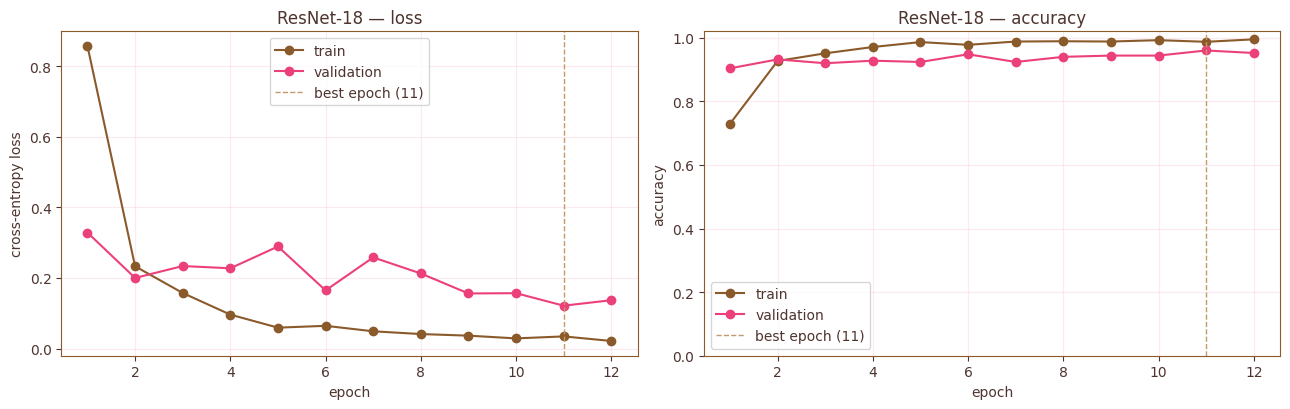

In [15]:
def plot_curves(history, title, best_epoch, path):
    epochs = range(1, len(history["train_loss"]) + 1)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.2))
    ax1.plot(epochs, history["train_loss"], "o-", color=BROWN, label="train")
    ax1.plot(epochs, history["val_loss"], "o-", color=PINK, label="validation")
    ax1.set(title=f"{title} — loss", xlabel="epoch", ylabel="cross-entropy loss")
    ax2.plot(epochs, history["train_acc"], "o-", color=BROWN, label="train")
    ax2.plot(epochs, history["val_acc"], "o-", color=PINK, label="validation")
    ax2.set(title=f"{title} — accuracy", xlabel="epoch", ylabel="accuracy", ylim=(0, 1.02))
    for ax in (ax1, ax2):
        ax.axvline(best_epoch, color=BROWN_LIGHT, ls="--", lw=1, label=f"best epoch ({best_epoch})")
        ax.grid(alpha=0.3)
        ax.legend()
    plt.tight_layout()
    plt.savefig(path, dpi=120)
    plt.show()

plot_curves(history, "ResNet-18", best_epoch, FIG_DIR / "curves.png")

**What the curves show:** ✍️ _Write one sentence after you run the notebook, from your own curves. Things to look at: how fast the validation loss drops, whether train and validation stay close (no overfitting) or separate (overfitting), and where the best epoch is._

## 6. After training: same test set, same metrics

In [16]:
after = evaluate(model, test_loader)
print_metrics("AFTER training (test set)", after)

AFTER training (test set)
  loss 0.1064 | accuracy 0.9679 | precision 0.9675 | recall 0.9713 | f1 0.9683


In [17]:
def df_to_markdown(df, fmt="{:.4f}"):
    """Tiny DataFrame → Markdown table helper (for the README)."""
    cell = lambda v: fmt.format(v) if isinstance(v, (float, np.floating)) else str(v)
    lines = ["| " + " | ".join([df.index.name or ""] + [str(c) for c in df.columns]) + " |",
             "|" + "---|" * (len(df.columns) + 1)]
    lines += ["| " + " | ".join([str(i)] + [cell(v) for v in row]) + " |" for i, row in zip(df.index, df.values)]
    return "\n".join(lines)

LABELS = {"loss": "Loss", "accuracy": "Accuracy", "precision": "Precision (macro)",
          "recall": "Recall (macro)", "f1": "F1 (macro)"}
before_after = pd.DataFrame({
    "Before training": [before[k] for k in METRICS],
    "After training":  [after[k] for k in METRICS],
}, index=pd.Index([LABELS[k] for k in METRICS], name="Metric (test set)"))
before_after["Change"] = before_after["After training"] - before_after["Before training"]
before_after.round(4)

,Before training,After training,Change
Metric (test set),,,
Loss,2.3584,0.1064,-2.2520
Accuracy,0.1285,0.9679,0.8394
Precision (macro),0.1521,0.9675,0.8154
Recall (macro),0.1088,0.9713,0.8624
F1 (macro),0.0646,0.9683,0.9037


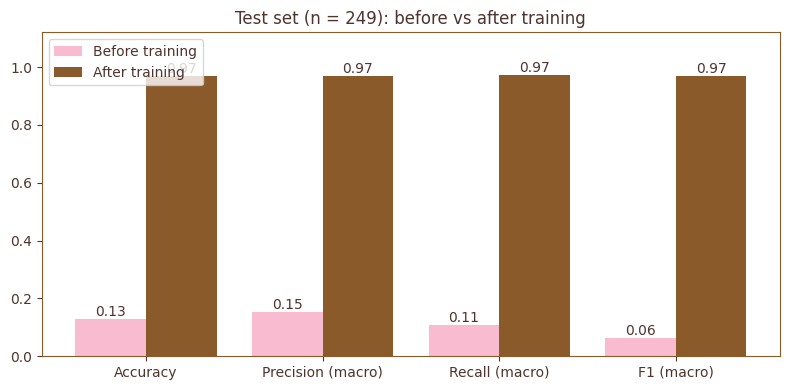

In [18]:
# Visual version of the table (loss is left out because it is on a different scale)
show = METRICS[1:]
x = np.arange(len(show))
fig, ax = plt.subplots(figsize=(8, 4))
b1 = ax.bar(x - 0.2, [before[k] for k in show], 0.4, label="Before training", color=PINK_LIGHT)
b2 = ax.bar(x + 0.2, [after[k] for k in show], 0.4, label="After training", color=BROWN)
ax.bar_label(b1, fmt="%.2f")
ax.bar_label(b2, fmt="%.2f")
ax.set_xticks(x, [LABELS[k] for k in show])
ax.set_ylim(0, 1.12)
ax.set_title(f"Test set (n = {len(test_ds)}): before vs after training")
ax.legend(loc="upper left")
plt.tight_layout()
plt.savefig(FIG_DIR / "before_after.png", dpi=120)
plt.show()

**What changed:** ✍️ _Write 2–3 sentences from your own numbers: where the model started (≈ guessing), where it ended, and why — the pretrained features + the new head learned to separate the varieties._

## 7. Where does it go wrong?

Confusion matrix: rows = true variety, columns = predicted variety. Before training the predictions are scattered (or all in one column); after training they should sit on the diagonal.

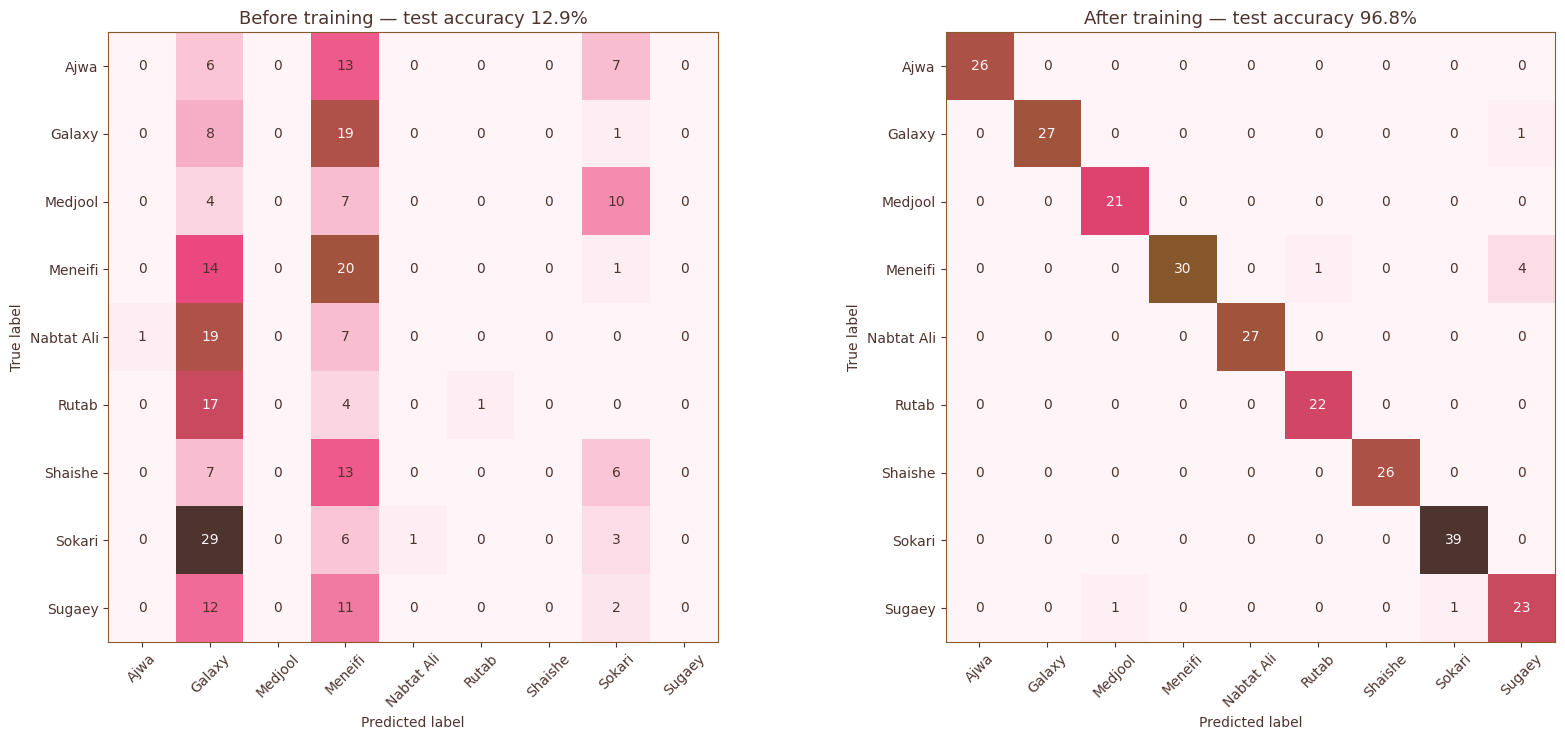

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(17, 7.5))
for ax, (title, m) in zip(axes, [("Before training", before), ("After training", after)]):
    cm = confusion_matrix(m["y_true"], m["y_pred"], labels=range(NUM_CLASSES))
    ConfusionMatrixDisplay(cm, display_labels=class_names).plot(ax=ax, cmap=CMAP_PINK_BROWN, colorbar=False, xticks_rotation=45)
    ax.set_title(f"{title} — test accuracy {m['accuracy']:.1%}", fontsize=13)
plt.tight_layout()
plt.savefig(FIG_DIR / "confusion_matrix.png", dpi=120)
plt.show()

In [20]:
print("Per-class results after training (test set):\n")
print(classification_report(after["y_true"], after["y_pred"], labels=range(NUM_CLASSES),
                            target_names=class_names, digits=3, zero_division=0))

cm_after = confusion_matrix(after["y_true"], after["y_pred"], labels=range(NUM_CLASSES))
confused = sorted(((cm_after[i, j], class_names[i], class_names[j])
                   for i in range(NUM_CLASSES) for j in range(NUM_CLASSES) if i != j and cm_after[i, j] > 0), reverse=True)
print("Most confused pairs:")
for n, true_c, pred_c in confused[:5]:
    print(f"  {true_c:>12} → predicted as {pred_c:<12} {n} time(s)")
if not confused:
    print("  none — no mistakes on the test set 🎉")

Per-class results after training (test set):

              precision    recall  f1-score   support

        Ajwa      1.000     1.000     1.000        26
      Galaxy      1.000     0.964     0.982        28
     Medjool      0.955     1.000     0.977        21
     Meneifi      1.000     0.857     0.923        35
  Nabtat Ali      1.000     1.000     1.000        27
       Rutab      0.957     1.000     0.978        22
     Shaishe      1.000     1.000     1.000        26
      Sokari      0.975     1.000     0.987        39
      Sugaey      0.821     0.920     0.868        25

    accuracy                          0.968       249
   macro avg      0.967     0.971     0.968       249
weighted avg      0.970     0.968     0.968       249

Most confused pairs:
       Meneifi → predicted as Sugaey       4 time(s)
        Sugaey → predicted as Sokari       1 time(s)
        Sugaey → predicted as Medjool      1 time(s)
       Meneifi → predicted as Rutab        1 time(s)
        Galaxy →

8 of 249 test images misclassified


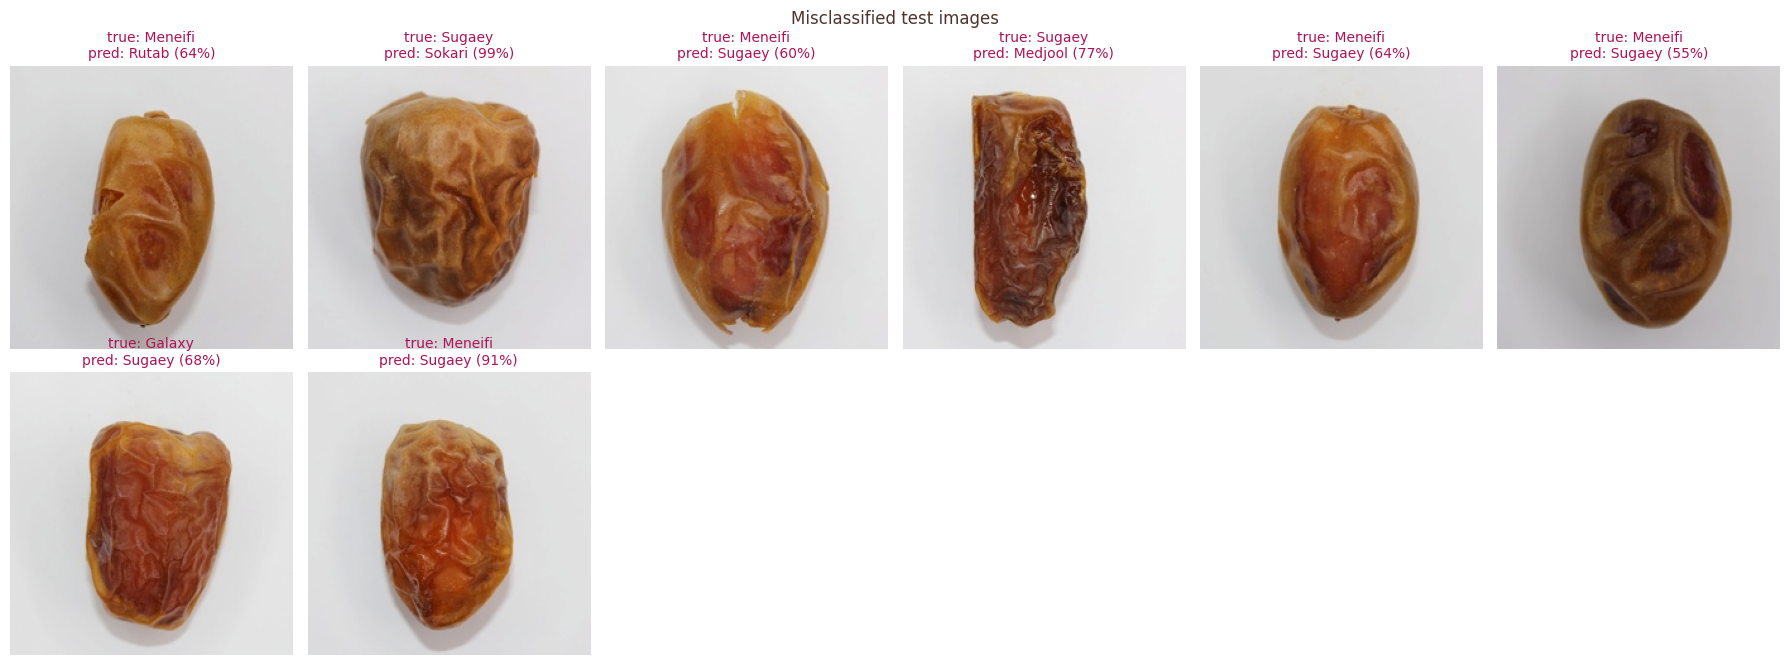

In [21]:
# Gallery of the mistakes (true label, predicted label, confidence)
wrong = np.where(after["y_pred"] != after["y_true"])[0]
print(f"{len(wrong)} of {len(test_ds)} test images misclassified")
if len(wrong) > 0:
    n = min(len(wrong), 12)
    cols = min(n, 6)
    rows = int(np.ceil(n / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(3 * cols, 3.4 * rows), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, k in zip(axes.flat, wrong[:n]):
        img, _ = test_ds[k]
        ax.imshow(denorm(img))
        ax.set_title(f"true: {class_names[after['y_true'][k]]}\npred: {class_names[after['y_pred'][k]]} "
                     f"({after['probs'][k].max():.0%})", fontsize=10, color=PINK_DARK)
    plt.suptitle("Misclassified test images")
    plt.tight_layout()
    plt.savefig(FIG_DIR / "errors.png", dpi=120)
    plt.show()

## 8. Looking inside the model: Grad-CAM

Grad-CAM shows **which pixels pushed the model towards its answer**. It takes the feature maps of the last convolutional block (`layer4`), weights each map by how much it increases the predicted class score (its average gradient), and adds them up into a heat-map.
If the heat sits **on the date** (skin, wrinkles, colour) and not on the background, the model learned the right thing.

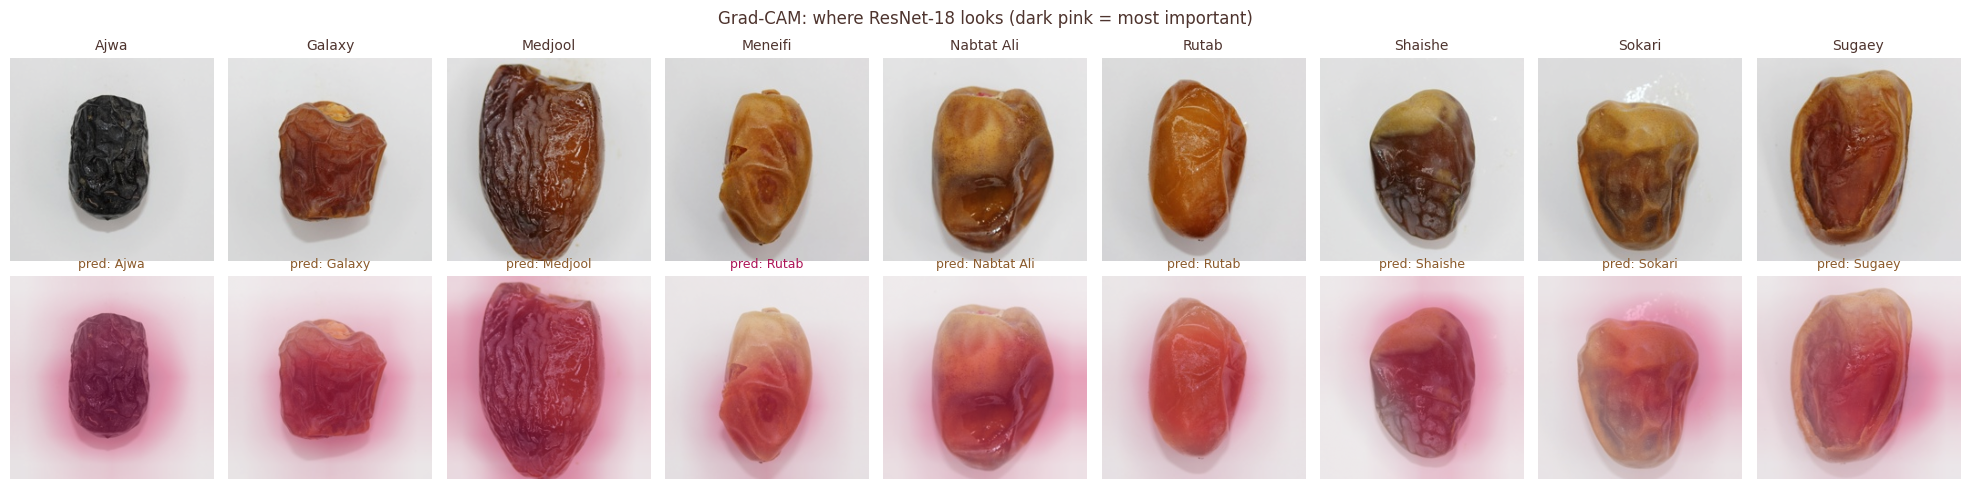

In [22]:
def grad_cam(model, x):
    """Grad-CAM heat-map for one normalised image tensor x (3,H,W). Returns (heat-map HxW in [0,1], predicted class)."""
    store = {}
    def save_grad(g):
        store["grad"] = g
    def forward_hook(module, inputs, output):
        store["act"] = output                 # feature maps of layer4: (1, 512, 7, 7)
        output.register_hook(save_grad)       # also catch their gradient on the way back

    handle = model.layer4.register_forward_hook(forward_hook)
    model.eval()
    logits = model(x.unsqueeze(0).to(device))
    pred = logits.argmax(dim=1).item()
    model.zero_grad()
    logits[0, pred].backward()                # gradient of the predicted class score
    handle.remove()

    weights = store["grad"].mean(dim=(2, 3), keepdim=True)               # importance of each feature map
    cam = F.relu((weights * store["act"]).sum(dim=1, keepdim=True))      # weighted sum, keep positive evidence
    cam = F.interpolate(cam, size=x.shape[1:], mode="bilinear", align_corners=False)[0, 0]
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
    return cam.detach().cpu().numpy(), pred

# One test image per variety
test_targets = targets[test_idx]
picks = [int(np.where(test_targets == c)[0][0]) for c in range(NUM_CLASSES) if (test_targets == c).any()]
fig, axes = plt.subplots(2, len(picks), figsize=(2.2 * len(picks), 5), squeeze=False)
for col, k in enumerate(picks):
    x, y = test_ds[k]
    cam, pred = grad_cam(model, x)
    axes[0, col].imshow(denorm(x))
    axes[0, col].set_title(class_names[y], fontsize=10)
    axes[1, col].imshow(denorm(x))
    axes[1, col].imshow(cam, cmap=CMAP_PINK_HEAT, alpha=0.45)
    axes[1, col].set_title(f"pred: {class_names[pred]}", fontsize=9, color=BROWN if pred == y else PINK_DARK)
    for ax in axes[:, col]:
        ax.axis("off")
plt.suptitle("Grad-CAM: where ResNet-18 looks (dark pink = most important)")
plt.tight_layout()
plt.savefig(FIG_DIR / "gradcam.png", dpi=120)
plt.show()
model.zero_grad()

## 9. Bonus: does transfer learning matter?

Same data, same split, same test set, but a **small CNN trained from scratch** (Day 1 / Lab 1B style): four blocks of *Conv → BatchNorm → ReLU → MaxPool*, then global average pooling and a linear layer. No pretrained knowledge at all.

In [23]:
class SmallCNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        def block(c_in, c_out):
            return nn.Sequential(nn.Conv2d(c_in, c_out, kernel_size=3, padding=1),
                                 nn.BatchNorm2d(c_out), nn.ReLU(), nn.MaxPool2d(2))
        self.features = nn.Sequential(block(3, 32), block(32, 64), block(64, 128), block(128, 256))
        self.pool = nn.AdaptiveAvgPool2d(1)                   # 256×14×14 → 256×1×1
        self.classifier = nn.Sequential(nn.Flatten(), nn.Dropout(0.3), nn.Linear(256, num_classes))

    def forward(self, x):
        return self.classifier(self.pool(self.features(x)))

if RUN_BASELINE_CNN:
    set_seed()
    cnn = SmallCNN(NUM_CLASSES).to(device)
    cnn_params = sum(p.numel() for p in cnn.parameters())
    print(f"SmallCNN: {cnn_params / 1e6:.2f} M parameters\n")
    cnn_opt = torch.optim.AdamW(cnn.parameters(), lr=LR_CNN, weight_decay=WEIGHT_DECAY)
    cnn_sched = torch.optim.lr_scheduler.CosineAnnealingLR(cnn_opt, T_max=EPOCHS_CNN)
    cnn_history, cnn_time = train_model(cnn, cnn_opt, cnn_sched, EPOCHS_CNN, "SmallCNN")
    cnn_after = evaluate(cnn, test_loader)
    print()
    print_metrics("SmallCNN AFTER training (test set)", cnn_after)

SmallCNN: 0.39 M parameters

[SmallCNN] epoch  1/20 | train loss 1.7331 acc 0.3603 | val loss 2.0344 acc 0.2088 | 8s
[SmallCNN] epoch  2/20 | train loss 1.3381 acc 0.5328 | val loss 1.2179 acc 0.5542 | 14s
[SmallCNN] epoch  3/20 | train loss 1.1721 acc 0.5698 | val loss 1.0963 acc 0.5020 | 22s
[SmallCNN] epoch  4/20 | train loss 1.0582 acc 0.6267 | val loss 0.8939 acc 0.6386 | 28s
[SmallCNN] epoch  5/20 | train loss 1.0387 acc 0.6155 | val loss 0.9300 acc 0.5542 | 35s
[SmallCNN] epoch  6/20 | train loss 0.9281 acc 0.6862 | val loss 0.9885 acc 0.5823 | 42s
[SmallCNN] epoch  7/20 | train loss 0.8519 acc 0.7095 | val loss 1.0319 acc 0.5944 | 49s
[SmallCNN] epoch  8/20 | train loss 0.7979 acc 0.7448 | val loss 0.7713 acc 0.6948 | 56s
[SmallCNN] epoch  9/20 | train loss 0.7145 acc 0.7836 | val loss 1.5498 acc 0.5502 | 63s
[SmallCNN] epoch 10/20 | train loss 0.6995 acc 0.7948 | val loss 0.6418 acc 0.7550 | 70s
[SmallCNN] epoch 11/20 | train loss 0.6557 acc 0.8009 | val loss 1.2673 acc 0.5582

,Pretrained,Parameters (M),Epochs,Train time (min),Test accuracy,Test F1 (macro)
Model,,,,,,
SmallCNN (from scratch),no,0.39,20,2.3,0.8273,0.8288
ResNet-18 (fine-tuned),yes (ImageNet),11.18,12,1.5,0.9679,0.9683


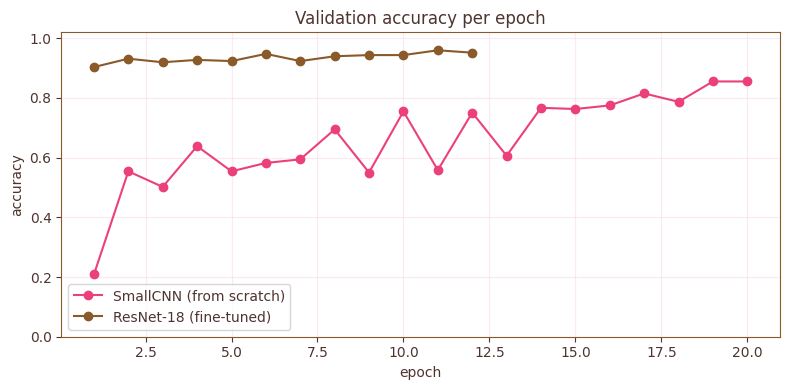

In [24]:
if RUN_BASELINE_CNN:
    comparison = pd.DataFrame({
        "Pretrained": ["no", "yes (ImageNet)"],
        "Parameters (M)": [f"{cnn_params / 1e6:.2f}", f"{n_params / 1e6:.2f}"],
        "Epochs": [str(EPOCHS_CNN), str(EPOCHS)],
        "Train time (min)": [f"{cnn_time / 60:.1f}", f"{train_time / 60:.1f}"],
        "Test accuracy": [cnn_after["accuracy"], after["accuracy"]],
        "Test F1 (macro)": [cnn_after["f1"], after["f1"]],
    }, index=pd.Index(["SmallCNN (from scratch)", "ResNet-18 (fine-tuned)"], name="Model"))
    display(comparison.round(4))

    fig, ax = plt.subplots(figsize=(8, 4))
    ax.plot(range(1, EPOCHS_CNN + 1), cnn_history["val_acc"], "o-", color=PINK, label="SmallCNN (from scratch)")
    ax.plot(range(1, EPOCHS + 1), history["val_acc"], "o-", color=BROWN, label="ResNet-18 (fine-tuned)")
    ax.set(title="Validation accuracy per epoch", xlabel="epoch", ylabel="accuracy", ylim=(0, 1.02))
    ax.grid(alpha=0.3)
    ax.legend()
    plt.tight_layout()
    plt.savefig(FIG_DIR / "transfer_vs_scratch.png", dpi=120)
    plt.show()

## 10. Try it: predictions on test images (and on your own photo)

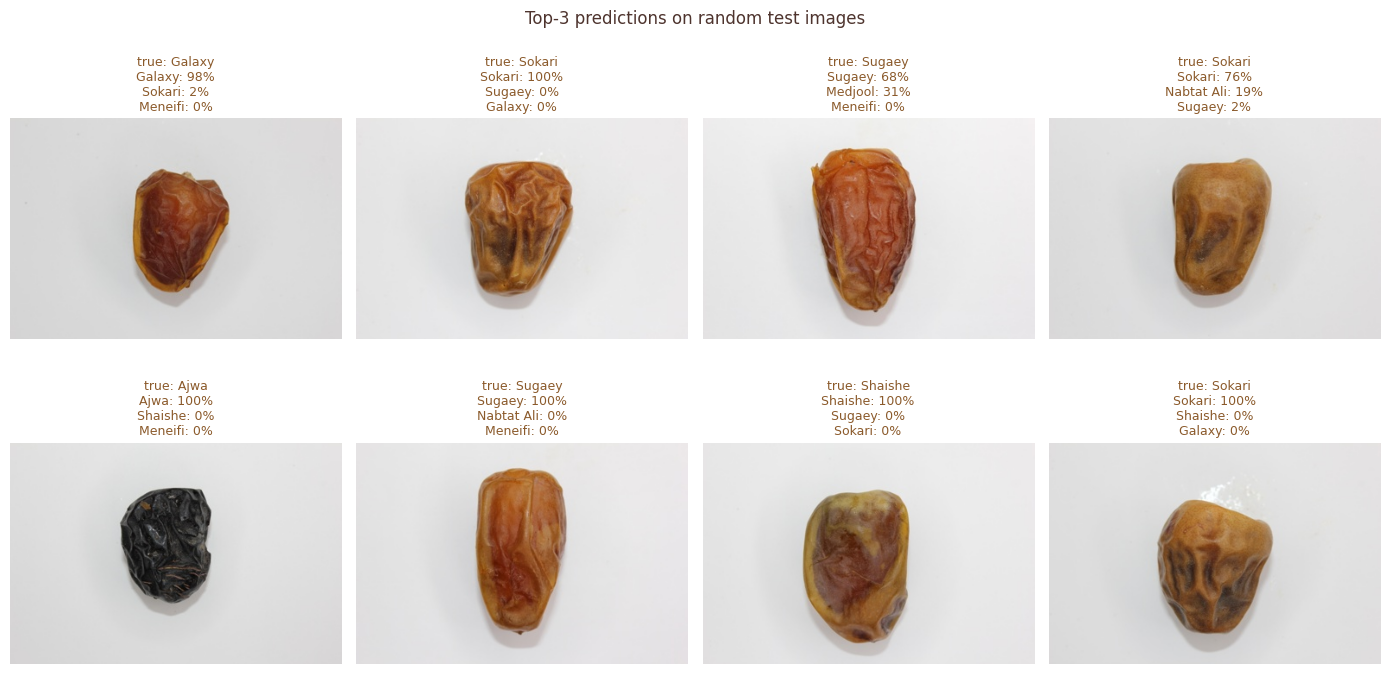

In [25]:
def predict_image(path, model, top_k=3):
    """Top-k predictions for any image file."""
    img = ImageOps.exif_transpose(Image.open(path)).convert("RGB")
    x = eval_tf(img).unsqueeze(0).to(device)
    model.eval()
    with torch.no_grad():
        probs = model(x).softmax(dim=1)[0].cpu()
    top = probs.topk(top_k)
    return img, [(class_names[i], p.item()) for p, i in zip(top.values, top.indices)]

# 8 random test images
rng = np.random.default_rng(7)
fig, axes = plt.subplots(2, 4, figsize=(14, 7.5))
for ax, k in zip(axes.flat, rng.choice(len(test_ds), size=8, replace=False)):
    path = full_ds.samples[test_idx[k]][0]
    img, top = predict_image(path, model)
    true_name = class_names[targets[test_idx[k]]]
    ax.imshow(img)
    ax.axis("off")
    ax.set_title(f"true: {true_name}\n" + "\n".join(f"{c}: {p:.0%}" for c, p in top), fontsize=9,
                 color=BROWN if top[0][0] == true_name else PINK_DARK)
plt.suptitle("Top-3 predictions on random test images")
plt.tight_layout()
plt.savefig(FIG_DIR / "predictions.png", dpi=120)
plt.show()

In [26]:
# Optional live demo: set to True, run this cell and upload a photo of a date
RUN_UPLOAD_DEMO = False
if RUN_UPLOAD_DEMO:
    from google.colab import files
    for name in files.upload():
        img, top = predict_image(name, model)
        plt.imshow(img)
        plt.axis("off")
        plt.title(" | ".join(f"{c} {p:.0%}" for c, p in top))
        plt.show()

## 11. Export results for the README

Every number in the README must come from this notebook. This cell writes them to `results/` (JSON + ready-to-paste Markdown tables) and zips `figures/` + `results/` for download.

In [27]:
hyperparams = pd.DataFrame({"Value": [
    "ResNet-18 (ImageNet weights) + new Linear(512 → 9) head", f"{IMG_SIZE}×{IMG_SIZE}", str(BATCH_SIZE), str(EPOCHS),
    f"{LR_BACKBONE:g} (backbone) / {LR_HEAD:g} (head)", f"AdamW (weight decay {WEIGHT_DECAY:g}) + cosine schedule",
    "CrossEntropyLoss", f"best validation epoch ({best_epoch})", f"{train_time / 60:.1f} min on {device.type.upper()}",
]}, index=pd.Index(["Model", "Input size", "Batch size", "Epochs", "Learning rate", "Optimizer",
                    "Loss", "Weights kept", "Training time"], name="Setting"))

summary = {
    "dataset": KAGGLE_DATASET, "classes": class_names, "n_images": len(full_ds),
    "duplicates_removed": n_dupes, "unreadable": n_bad,
    "split": {"train": len(train_idx), "val": len(val_idx), "test": len(test_idx)},
    "hyperparameters": {"img_size": IMG_SIZE, "batch_size": BATCH_SIZE, "epochs": EPOCHS, "lr_backbone": LR_BACKBONE,
                        "lr_head": LR_HEAD, "weight_decay": WEIGHT_DECAY, "seed": SEED},
    "before": {k: float(before[k]) for k in METRICS},
    "after": {k: float(after[k]) for k in METRICS},
    "best_epoch": best_epoch, "train_time_min": round(train_time / 60, 2), "history": history,
}
if RUN_BASELINE_CNN:
    summary["small_cnn"] = {"after": {k: float(cnn_after[k]) for k in METRICS},
                            "train_time_min": round(cnn_time / 60, 2), "history": cnn_history}
(RESULTS_DIR / "metrics.json").write_text(json.dumps(summary, indent=2))

md_parts = [
    f"**Images used:** {len(full_ds)} · **Exact duplicates removed:** {n_dupes} · **Classes:** {NUM_CLASSES}",
    "#### Split per class\n" + df_to_markdown(split_table),
    "#### Training setup\n" + df_to_markdown(hyperparams),
    f"#### Before vs after training (same test set, n = {len(test_ds)})\n" + df_to_markdown(before_after),
]
if RUN_BASELINE_CNN:
    md_parts.append("#### Transfer learning vs training from scratch\n" + df_to_markdown(comparison))
(RESULTS_DIR / "README_results.md").write_text("\n\n".join(md_parts) + "\n")
print((RESULTS_DIR / "README_results.md").read_text())

**Images used:** 1658 · **Exact duplicates removed:** 0 · **Classes:** 9

#### Split per class
| Variety | train | val | test | total |
|---|---|---|---|---|
| Ajwa | 122 | 27 | 26 | 175 |
| Galaxy | 133 | 29 | 28 | 190 |
| Medjool | 94 | 20 | 21 | 135 |
| Meneifi | 162 | 35 | 35 | 232 |
| Nabtat Ali | 124 | 26 | 27 | 177 |
| Rutab | 102 | 22 | 22 | 146 |
| Shaishe | 120 | 25 | 26 | 171 |
| Sokari | 185 | 40 | 39 | 264 |
| Sugaey | 118 | 25 | 25 | 168 |
| TOTAL | 1160 | 249 | 249 | 1658 |

#### Training setup
| Setting | Value |
|---|---|
| Model | ResNet-18 (ImageNet weights) + new Linear(512 → 9) head |
| Input size | 224×224 |
| Batch size | 32 |
| Epochs | 12 |
| Learning rate | 0.0001 (backbone) / 0.001 (head) |
| Optimizer | AdamW (weight decay 0.0001) + cosine schedule |
| Loss | CrossEntropyLoss |
| Weights kept | best validation epoch (11) |
| Training time | 1.5 min on CUDA |

#### Before vs after training (same test set, n = 249)
| Metric (test set) | Before training | After

In [28]:
with zipfile.ZipFile("project_outputs.zip", "w") as z:
    for p in sorted([*FIG_DIR.glob("*.png"), *RESULTS_DIR.glob("*")]):
        z.write(p)
print("Saved project_outputs.zip →", [p.name for p in sorted(FIG_DIR.glob("*.png"))])
try:
    from google.colab import files
    files.download("project_outputs.zip")
except ImportError:
    pass

Saved project_outputs.zip → ['before_after.png', 'class_counts.png', 'confusion_matrix.png', 'curves.png', 'errors.png', 'gradcam.png', 'predictions.png', 'samples.png', 'transfer_vs_scratch.png']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 12. Conclusions & next steps

✍️ _Fill in from your own results:_

* **Result:** test accuracy went from ___ (before) to ___ (after training).
* **Hardest varieties:** ___ and ___ were confused most often, because ___.
* **Transfer learning:** the pretrained ResNet-18 beat the from-scratch CNN by ___ points of accuracy.

**Limitations**
* All photos come from one controlled setup (same background and light). Real-world phone photos may look different, so accuracy there will likely be lower.
* Several photos may show the *same* fruit from different sides. If one side is in train and another in test, the test score can be optimistic.

**Next steps**
* Test on our own phone photos of dates from the market (the upload cell above).
* Add more varieties popular in Saudi Arabia (Khalas, Barhi, Segae …).
* Export the model to a mobile app for sorting and shopping.